In [35]:
import yfinance as yf
import pandas as pd
import numpy as np
import sklearn as sk
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [36]:
commodity_tickers = {
    # Agricultural Commodities
    'ZC=F': 'Corn',
    'ZS=F': 'Soybeans', 
    'ZW=F': 'Wheat',
    'ZO=F': 'Oats',
    'ZR=F': 'Rough Rice',
    'ZM=F': 'Soybean Meal',
    'ZL=F': 'Soybean Oil',
    
    # Energy Commodities
    'CL=F': 'Crude Oil WTI',
    'BZ=F': 'Brent Crude Oil',
    'NG=F': 'Natural Gas',
    'RB=F': 'RBOB Gasoline',
    'HO=F': 'Heating Oil',
    
    # Metals
    'GC=F': 'Gold',
    'SI=F': 'Silver',
    'HG=F': 'Copper',
    'PL=F': 'Platinum',
    
    # Softs
    'KC=F': 'Coffee',
    'CT=F': 'Cotton',
    'SB=F': 'Sugar',
    'CC=F': 'Cocoa',
    'OJ=F': 'Orange Juice',
    
    # Livestock
    'LE=F': 'Live Cattle',
    'GF=F': 'Feeder Cattle',
    'HE=F': 'Lean Hogs'
}
tickers = list(commodity_tickers    .keys())
data=yf.download(tickers, start='2010-01-01', end='2025-01-01')
returns=data.pct_change().dropna()

[*********************100%***********************]  24 of 24 completed


In [37]:
if isinstance(data.columns, pd.MultiIndex):
    prices = data['Close'].copy()
    volumes = data['Volume'].copy() if 'Volume' in data.columns.levels[0] else None
else:
    prices = data['Close'].to_frame()
    volumes = data['Volume'].to_frame() if 'Volume' in data.columns else None

prices.columns = [commodity_tickers[col] for col in prices.columns]
if volumes is not None:
    volumes.columns = [commodity_tickers[col] for col in volumes.columns]


In [38]:
missing_pct = (prices.isnull().sum() / len(prices) * 100).round(2)
high_missing = missing_pct[missing_pct > 20].index.tolist()
if high_missing:
    prices = prices.drop(columns=high_missing)
prices_clean = prices.fillna(method='ffill', limit=5).fillna(method='bfill', limit=5).dropna()

In [39]:
simple_returns = prices_clean.pct_change().dropna()
log_returns = np.log(prices_clean / prices_clean.shift(1)).dropna()
returns_final = log_returns.copy()


In [40]:
commodity_groups = {
    'Agricultural': ['Corn', 'Soybeans', 'Wheat', 'Oats', 'Rough Rice', 'Soybean Meal', 'Soybean Oil'],
    'Energy': ['Crude Oil WTI', 'Brent Crude Oil', 'Natural Gas', 'RBOB Gasoline', 'Heating Oil'],
    'Metals': ['Gold', 'Silver', 'Copper', 'Platinum'],
    'Softs': ['Coffee', 'Cotton', 'Sugar', 'Cocoa', 'Orange Juice'],
    'Livestock': ['Live Cattle', 'Feeder Cattle', 'Lean Hogs']
}
available_groups = {g: [c for c in v if c in prices_clean.columns] for g,v in commodity_groups.items()}

In [ ]:
summary_stats = pd.DataFrame({
    'Mean Return (%)': returns_final.mean() * 252 * 100,
    'Volatility (%)': returns_final.std() * np.sqrt(252) * 100,
    'Sharpe Ratio': (returns_final.mean() / returns_final.std()) * np.sqrt(252),
    'Skewness': returns_final.skew(),
    'Kurtosis': returns_final.kurtosis(),
    'Min (%)': returns_final.min() * 100,
    'Max (%)': returns_final.max() * 100
}).round(3)
summary_stats.to_csv('outputs/summary_statistics.csv')
summary_stats.head(10)

,Mean Return (%),Volatility (%),Sharpe Ratio,Skewness,Kurtosis,Min (%),Max (%)
Brent Crude Oil,2.022,35.099,0.058,-0.485,12.170,-27.575,19.077
Cocoa,8.767,32.114,0.273,-0.969,14.694,-26.057,12.805
Crude Oil WTI,3.167,40.879,0.077,0.070,24.970,-28.221,31.963
Cotton,-0.772,28.607,-0.027,-1.299,16.871,-27.292,6.964
Gold,5.762,15.983,0.360,-0.592,5.860,-9.821,5.778
Feeder Cattle,6.837,17.384,0.393,0.659,12.679,-8.611,11.279
Lean Hogs,0.374,39.020,0.010,-1.428,25.737,-26.815,23.634
Copper,1.337,22.636,0.059,-0.105,1.903,-7.551,7.199
Heating Oil,2.219,34.281,0.065,-0.812,11.235,-24.754,12.357
Coffee,5.812,33.156,0.175,0.225,1.322,-9.021,11.789


In [ ]:
prices_clean.to_csv('data/commodity_prices_clean.csv')
returns_final.to_csv('outputs/commodity_returns_log.csv')
simple_returns.to_csv('outputs/commodity_returns_simple.csv')
if volumes is not None:
    volumes_clean = volumes.loc[prices_clean.index, prices_clean.columns]
    volumes_clean.to_csv('outputs/commodity_volumes.csv')

In [43]:
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
warnings.filterwarnings('ignore')


In [ ]:
sns.set_style('whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 10
prices = pd.read_csv('data/commodity_prices_clean.csv', index_col=0, parse_dates=True)
returns = pd.read_csv('outputs/commodity_returns_log.csv', index_col=0, parse_dates=True)
commodities = returns.columns.tolist()

In [ ]:
desc_stats = pd.DataFrame({
    'Count': returns.count(),
    'Mean (%)': returns.mean() * 252 * 100,
    'Std Dev (%)': returns.std() * np.sqrt(252) * 100,
    'Min (%)': returns.min() * 100,
    'Max (%)': returns.max() * 100,
    'Skewness': returns.skew(),
    'Kurtosis': returns.kurtosis(),
    'Sharpe': (returns.mean() / returns.std()) * np.sqrt(252)
}).round(4)
desc_stats.to_csv('outputs/descriptive_statistics_detailed.csv')


In [ ]:
normality_results = []
for c in commodities:
    jb_stat, jb_pvalue = stats.jarque_bera(returns[c].dropna())
    normality_results.append({
        'Commodity': c,
        'JB Statistic': round(jb_stat, 2),
        'p-value': round(jb_pvalue, 4),
        'Normal?': 'Yes' if jb_pvalue > 0.05 else 'No'
    })
normality_df = pd.DataFrame(normality_results)
normality_df.to_csv('outputs/normality_tests.csv', index=False)


In [ ]:
def test_stationarity(series):
    adf_result = adfuller(series.dropna(), autolag='AIC')
    kpss_result = kpss(series.dropna(), regression='c', nlags='auto')
    return {
        'ADF_stat': adf_result[0],
        'ADF_pvalue': adf_result[1],
        'ADF_stationary': 'Yes' if adf_result[1] < 0.05 else 'No',
        'KPSS_stat': kpss_result[0],
        'KPSS_pvalue': kpss_result[1],
        'KPSS_stationary': 'Yes' if kpss_result[1] > 0.05 else 'No'
    }
stationarity_results = []
for c in commodities:
    result = test_stationarity(returns[c])
    result['Commodity'] = c
    stationarity_results.append(result)
stationarity_df = pd.DataFrame(stationarity_results)
stationarity_df = stationarity_df[['Commodity', 'ADF_pvalue', 'ADF_stationary', 'KPSS_pvalue', 'KPSS_stationary']]
stationarity_df.to_csv('outputs/stationarity_tests.csv', index=False)

corr_matrix = returns.corr()
corr_matrix.to_csv('outputs/correlation_matrix.csv')
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        val = corr_matrix.iloc[i, j]
        if abs(val) > 0.5:
            high_corr_pairs.append({'Commodity 1': corr_matrix.columns[i], 'Commodity 2': corr_matrix.columns[j], 'Correlation': round(val, 3)})
high_corr_df = pd.DataFrame(high_corr_pairs).sort_values('Correlation', key=abs, ascending=False)
high_corr_df.to_csv('outputs/high_correlations.csv', index=False)

In [ ]:
returns_with_months = returns.copy()
returns_with_months['Month'] = returns_with_months.index.month
monthly_avg = returns_with_months.groupby('Month')[commodities].mean() * 100
monthly_avg.to_csv('outputs/monthly_average_returns.csv')
seasonal_test_results = []
for c in commodities:
    monthly_groups = [returns_with_months[returns_with_months['Month'] == m][c].dropna() for m in range(1, 13)]
    monthly_groups = [g for g in monthly_groups if len(g) > 0]
    f_stat, p_value = stats.f_oneway(*monthly_groups)
    seasonal_test_results.append({
        'Commodity': c,
        'F-statistic': round(f_stat, 4),
        'p-value': round(p_value, 4),
        'Seasonal Effect?': 'Yes' if p_value < 0.1 else 'No',
        'Significance': '***' if p_value < 0.01 else ('**' if p_value < 0.05 else '*' if p_value < 0.1 else '')
    })
seasonal_df = pd.DataFrame(seasonal_test_results)
seasonal_df.to_csv('outputs/seasonal_effects_anova.csv', index=False)

In [ ]:
monthly_stats = pd.DataFrame({
    'Mean': monthly_avg.mean(axis=1),
    'Std': monthly_avg.std(axis=1),
    'Min': monthly_avg.min(axis=1),
    'Max': monthly_avg.max(axis=1)
}).round(3)
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_stats.index = month_names
monthly_stats.to_csv('outputs/monthly_return_stats.csv')


In [ ]:
rolling_vol = returns.rolling(window=21).std() * np.sqrt(252) * 100
vol_stats = pd.DataFrame({
    'Mean Vol (%)': rolling_vol.mean(),
    'Max Vol (%)': rolling_vol.max(),
    'Min Vol (%)': rolling_vol.min(),
    'Vol of Vol': rolling_vol.std()
}).round(2)
vol_stats.to_csv('outputs/volatility_statistics.csv')

In [ ]:
from statsmodels.tsa.seasonal import STL
import os
import re

# Function to sanitize commodity names for filenames
def sanitize_filename(name):
    return re.sub(r'[^A-Za-z0-9]+', '_', name)

# Load all commodity returns
returns = pd.read_csv('outputs/commodity_returns_log.csv', index_col=0, parse_dates=True)

# Ensure output directory exists
os.makedirs('outputs/stl', exist_ok=True)

decomp_results = {}

for commodity in returns.columns:
    series = returns[commodity].dropna()
    if len(series) < 500:
        print(f"Skipping {commodity} due to short series length.")
        continue
    
    filename_safe = sanitize_filename(commodity)
    
    try:
        stl = STL(series, period=252, robust=True)
        result = stl.fit()
        decomp_results[commodity] = {
            'trend': result.trend,
            'seasonal': result.seasonal,
            'resid': result.resid
        }
        # Save components
        comp_df = pd.DataFrame({'Trend': result.trend, 'Seasonal': result.seasonal, 'Residual': result.resid})
        comp_df.to_csv(f'outputs/stl/{filename_safe}_stl_components.csv', index=False)
        
        # Plot decomposition
        fig, axs = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
        axs[0].plot(series, label='Original Price')
        axs[0].set_title(f"{commodity} Price")
        axs[1].plot(result.trend, label='Trend', color='blue')
        axs[1].set_title("Trend")
        axs[2].plot(result.seasonal, label='Seasonal', color='orange')
        axs[2].set_title("Seasonal")
        axs[3].plot(result.resid, label='Residual', color='red')
        axs[3].set_title("Residual")
        plt.tight_layout()
        plt.savefig(f'outputs/stl/{filename_safe}_stl_plot.png')
        plt.close(fig)
        
        print(f"STL decomposition complete and saved for {commodity}")
    except Exception as e:
        print(f"Failed to process {commodity}: {e}")

# Save seasonality strength ranking
seasonality_strength = {c: np.std(decomp_results[c]['seasonal']) for c in decomp_results}
seasonality_strength_df = pd.DataFrame.from_dict(seasonality_strength, orient='index', columns=['SeasonalityStd'])

STL decomposition complete and saved for Brent Crude Oil
STL decomposition complete and saved for Cocoa
STL decomposition complete and saved for Crude Oil WTI
STL decomposition complete and saved for Cotton
STL decomposition complete and saved for Gold
STL decomposition complete and saved for Feeder Cattle
STL decomposition complete and saved for Lean Hogs
STL decomposition complete and saved for Copper
STL decomposition complete and saved for Heating Oil
STL decomposition complete and saved for Coffee
STL decomposition complete and saved for Live Cattle
STL decomposition complete and saved for Natural Gas
STL decomposition complete and saved for Orange Juice
STL decomposition complete and saved for Platinum
STL decomposition complete and saved for RBOB Gasoline
STL decomposition complete and saved for Sugar
STL decomposition complete and saved for Silver
STL decomposition complete and saved for Corn
STL decomposition complete and saved for Soybean Oil
STL decomposition complete and sa

In [ ]:
seasonality_metrics = {}
for c in decomp_results:
    seasonal_var = np.var(decomp_results[c]['seasonal'])
    resid_var = np.var(decomp_results[c]['resid'])
    total_var = seasonal_var + resid_var
    
    seasonality_metrics[c] = {
        'Seasonal_Std': np.std(decomp_results[c]['seasonal']),
        'Seasonal_Var': seasonal_var,
        'Residual_Var': resid_var,
        'Seasonality_Strength': seasonal_var / total_var if total_var > 0 else 0,
        'Seasonality_Strength_Pct': (seasonal_var / total_var * 100) if total_var > 0 else 0
    }

# Save comprehensive metrics
seasonality_df = pd.DataFrame.from_dict(seasonality_metrics, orient='index')
seasonality_df = seasonality_df.sort_values('Seasonality_Strength', ascending=False)
seasonality_df.to_csv('outputs/stl/seasonality_strength.csv')

print("\nCommodities by seasonality strength:")
print(seasonality_df[['Seasonality_Strength_Pct', 'Seasonal_Std']])



Commodities by seasonality strength:
                 Seasonality_Strength_Pct  Seasonal_Std
Sugar                           31.251300      0.011706
Orange Juice                    30.909059      0.012813
Natural Gas                     28.845099      0.020959
Soybean Oil                     28.763961      0.008918
Copper                          28.498127      0.008139
Coffee                          28.309575      0.011969
Wheat                           28.249541      0.011613
Cotton                          27.854698      0.010120
Cocoa                           27.794999      0.011282
Soybeans                        26.804351      0.007420
Platinum                        26.039564      0.008723
Oats                            25.691898      0.012412
Corn                            25.629667      0.009490
Gold                            24.563890      0.005374
Silver                          24.283466      0.010358
Live Cattle                     22.361385      0.005579
Soybean Me

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -196.5     -196.4*   4.640e-86     -196.5*
1       -196.7      -195.7   3.795e-86      -196.3
2      -196.7*      -194.7  3.769e-86*      -196.0
3       -196.7      -193.8   3.901e-86      -195.6
4       -196.6      -192.8   4.063e-86      -195.2
5       -196.5      -191.7   4.476e-86      -194.8
6       -196.4      -190.7   4.826e-86      -194.4
7       -196.3      -189.6   5.350e-86      -194.0
8       -196.2      -188.6   5.899e-86      -193.5
9       -196.1      -187.5   6.536e-86      -193.1
10      -196.1      -186.5   7.134e-86      -192.6
11      -196.0      -185.4   7.867e-86      -192.2
12      -195.8      -184.3   8.894e-86      -191.8
13      -195.7      -183.3   9.894e-86      -191.3
14      -195.6      -182.2   1.093e-85      -190.9
15      -195.6      -181.2   1.191e-85      -190.4
-------------------------------

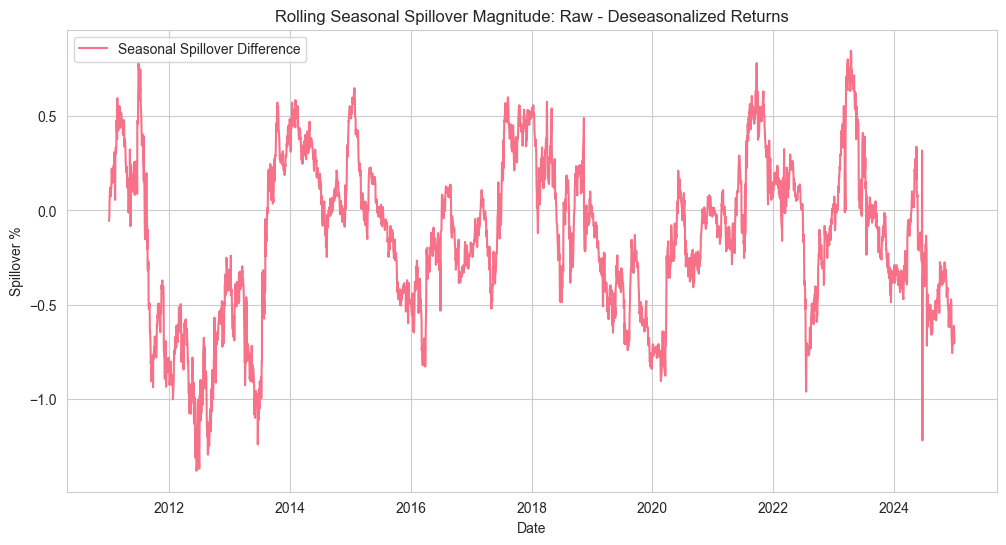

In [ ]:
from statsmodels.tsa.api import VAR
import matplotlib.pyplot as plt
import os
import re

def sanitize(name):
    return re.sub(r'[^A-Za-z0-9]+', '_', name)

# Load raw returns
raw_returns = pd.read_csv('outputs/commodity_returns_log.csv', index_col=0, parse_dates=True)

# Load seasonal components
seasonal_components = {}
for commodity in raw_returns.columns:
    safe_name = sanitize(commodity)
    filepath = f'outputs/stl/{safe_name}_stl_components.csv'
    if os.path.exists(filepath):
        seasonal = pd.read_csv(filepath, index_col=0, parse_dates=True)['Seasonal']
        seasonal_components[commodity] = seasonal
seasonal_df = pd.DataFrame(seasonal_components)

# Align indices
seasonal_df = seasonal_df.loc[raw_returns.index.intersection(seasonal_df.index)]

# Deseasonalized returns = raw returns - seasonal component
deseasonalized_returns = raw_returns.loc[seasonal_df.index] - seasonal_df.fillna(0)

# Select optimal lag order by AIC criterion
def select_lag(data, maxlags=15):
    model = VAR(data)
    lag_results = model.select_order(maxlags)
    print(lag_results.summary())
    return lag_results.aic

lag_order = select_lag(raw_returns)

# Fit VAR models
var_raw = VAR(raw_returns).fit(lag_order)
var_deseasonalized = VAR(deseasonalized_returns).fit(lag_order)

# Diebold-Yilmaz spillover index function (fix for ndarray)
def diebold_yilmaz(var_res, horizon=10):
    fevd = var_res.fevd(horizon)
    total_variance = fevd.decomp  # numpy ndarray of shape (nvar,nvar,horizon)
    # We take the last horizon slice for total spillover
    last_horizon_fevd = total_variance[:, :, -1]
    off_diag_sum = np.sum(last_horizon_fevd) - np.trace(last_horizon_fevd)
    total_spillover = 100 * off_diag_sum / np.sum(last_horizon_fevd)
    return total_spillover

spill_raw = diebold_yilmaz(var_raw)
spill_deseasonalized = diebold_yilmaz(var_deseasonalized)

print(f'Total spillover index (raw returns): {spill_raw:.2f}%')
print(f'Total spillover index (deseasonalized): {spill_deseasonalized:.2f}%')
print(f'Estimated seasonal spillover magnitude: {spill_raw - spill_deseasonalized:.2f}%')

# Rolling window analysis
window = 252
dates = raw_returns.index[window:]

rolling_diff = []

for start in range(len(raw_returns) - window):
    end = start + window
    sub_raw = raw_returns.iloc[start:end]
    sub_ds = deseasonalized_returns.iloc[start:end]

    var_sub_raw = VAR(sub_raw).fit(lag_order)
    var_sub_ds = VAR(sub_ds).fit(lag_order)

    spill_sub_raw = diebold_yilmaz(var_sub_raw)
    spill_sub_ds = diebold_yilmaz(var_sub_ds)

    rolling_diff.append(spill_sub_raw - spill_sub_ds)

plt.figure(figsize=(12, 6))
plt.plot(dates, rolling_diff, label='Seasonal Spillover Difference')
plt.title('Rolling Seasonal Spillover Magnitude: Raw - Deseasonalized Returns')
plt.xlabel('Date')
plt.ylabel('Spillover %')
plt.legend()
plt.show()


In [ ]:
from statsmodels.tsa.stattools import grangercausalitytests

def sanitize(name):
    return re.sub(r'[^A-Za-z0-9]+', '_', name)

# Load commodity names
commodity_list = pd.read_csv('data/commodity_prices_clean.csv', index_col=0).columns.tolist()

# Load all STL seasonal series
seasonal_dict = {}
for commodity in commodity_list:
    fname = f'stl_output/{sanitize(commodity)}_stl_components.csv'
    if os.path.exists(fname):
        seasonal = pd.read_csv(fname, index_col=0, parse_dates=True)['Seasonal']
        seasonal_dict[commodity] = seasonal

# Align all series by index (intersection)
common_idx = None
for series in seasonal_dict.values():
    if common_idx is None:
        common_idx = series.index
    else:
        common_idx = common_idx.intersection(series.index)
for k in seasonal_dict:
    seasonal_dict[k] = seasonal_dict[k].loc[common_idx]

results = []  # Store results for export

maxlag = 2  # Use system-wide optimal lag, or you can select per pair with AIC/BIC

for i, c1 in enumerate(commodity_list):
    for j, c2 in enumerate(commodity_list):
        if i == j:
            continue
        if c1 not in seasonal_dict or c2 not in seasonal_dict:
            continue
        data = pd.DataFrame({c1: seasonal_dict[c1], c2: seasonal_dict[c2]})
        data = data.dropna()
        # Test c1 -> c2 (does c1's seasonality predict c2's)
        try:
            gc_res = grangercausalitytests(data[[c2, c1]], maxlag=maxlag, verbose=False)
            pval = min([gc_res[lag][0]['ssr_ftest'][1] for lag in range(1, maxlag+1)])
            results.append({'from': c1, 'to': c2, 'min_pval': pval})
        except Exception as e:
            print(f"Pair {c1}-{c2} failed: {str(e)}")

results_df = pd.DataFrame(results)
results_df.to_csv('outputs/pairwise_seasonal_granger.csv')

# Filter significant results for reporting table
sig_results = results_df[results_df['min_pval'] < 0.05].sort_values('min_pval')
sig_results.to_csv('outputs/significant_pairwise_seasonal_granger.csv')

print('Pairwise Granger causality analysis complete. Significant effects saved in significant_pairwise_seasonal_granger.csv.')

Pairwise Granger causality analysis complete. Significant effects saved in significant_pairwise_seasonal_granger.csv.


In [ ]:
sector_members = {
    "Agriculture": ['Corn', 'Soybeans', 'Wheat', 'Oats', 'Rough Rice', 'Soybean Meal', 'Soybean Oil'],
    "Energy": ['Crude Oil WTI', 'Brent Crude Oil', 'Natural Gas', 'RBOB Gasoline', 'Heating Oil'],
    "Metals": ['Gold', 'Silver', 'Copper', 'Platinum'],
    "Softs": ['Coffee', 'Cotton', 'Sugar', 'Cocoa', 'Orange Juice'],
    "Livestock": ['Live Cattle', 'Feeder Cattle', 'Lean Hogs'],
}

import pandas as pd
from statsmodels.tsa.stattools import grangercausalitytests

sector_seasonals = {}
for sector, members in sector_members.items():
    # Extract the seasonal series for all sector commodities
    df_sector = pd.concat([seasonal_dict[c] for c in members if c in seasonal_dict], axis=1)
    # Drop any rows with all NaNs to keep aligned data
    df_sector = df_sector.dropna(how='all')
    # Compute standard deviation per commodity, avoid division by zero
    std_dev = df_sector.std(axis=0).replace(0, np.nan)
    # Standardize by dividing each series by its std deviation
    df_sector_std = df_sector.divide(std_dev, axis=1)
    # Take the mean across commodities to get sector-level seasonal series
    sector_seasonals[sector] = df_sector_std.mean(axis=1)

# Market-wise Granger
results = []
maxlag = 2
for sec1 in sector_seasonals:
    for sec2 in sector_seasonals:
        if sec1 == sec2: continue
        df = pd.DataFrame({sec1: sector_seasonals[sec1], sec2: sector_seasonals[sec2]}).dropna()
        try:
            gc_res = grangercausalitytests(df[[sec2, sec1]], maxlag=maxlag, verbose=False)
            min_pval = min(gc_res[lag][0]['ssr_ftest'][1] for lag in range(1, maxlag+1))
            results.append({'from': sec1, 'to': sec2, 'min_pval': min_pval})
        except Exception as e:
            print(f"Error for {sec1}->{sec2}: {e}")

results_df = pd.DataFrame(results)
results_df = results_df.sort_values('min_pval')
results_df.to_csv('outputs/sectoral_seasonal_granger.csv', index=False)
print(results_df)

           from           to  min_pval
5        Energy       Metals  0.000007
17    Livestock       Energy  0.000403
7        Energy    Livestock  0.000493
19    Livestock        Softs  0.000559
3   Agriculture    Livestock  0.000663
8        Metals  Agriculture  0.011677
10       Metals        Softs  0.016928
2   Agriculture        Softs  0.021834
9        Metals       Energy  0.023166
6        Energy        Softs  0.024007
0   Agriculture       Energy  0.033301
18    Livestock       Metals  0.045953
4        Energy  Agriculture  0.072458
1   Agriculture       Metals  0.123130
12        Softs  Agriculture  0.157274
14        Softs       Metals  0.165702
11       Metals    Livestock  0.370252
13        Softs       Energy  0.429210
15        Softs    Livestock  0.453055
16    Livestock  Agriculture  0.774011


In [ ]:
import pandas as pd
from statsmodels.tsa.stattools import grangercausalitytests

sector_members = {
    "Agriculture": ['Corn', 'Soybeans', 'Wheat', 'Oats', 'Rough Rice', 'Soybean Meal', 'Soybean Oil'],
    "Energy": ['Crude Oil WTI', 'Brent Crude Oil', 'Natural Gas', 'RBOB Gasoline', 'Heating Oil'],
    "Metals": ['Gold', 'Silver', 'Copper', 'Platinum'],
    "Softs": ['Coffee', 'Cotton', 'Sugar', 'Cocoa', 'Orange Juice'],
    "Livestock": ['Live Cattle', 'Feeder Cattle', 'Lean Hogs'],
}

sector_seasonals = {}
for sector, members in sector_members.items():
    # Extract the seasonal series for all sector commodities
    df_sector = pd.concat([seasonal_dict[c] for c in members if c in seasonal_dict], axis=1)
    # Drop any rows with all NaNs to keep aligned data
    df_sector = df_sector.dropna(how='all')
    # Compute standard deviation per commodity, avoid division by zero
    std_dev = df_sector.std(axis=0).replace(0, np.nan)
    # Standardize by dividing each series by its std deviation
    df_sector_std = df_sector.divide(std_dev, axis=1)
    # Take the mean across commodities to get sector-level seasonal series
    sector_seasonals[sector] = df_sector_std.mean(axis=1)

results = []
maxlag = 2
for sec1 in sector_seasonals:
    for sec2 in sector_seasonals:
        if sec1 == sec2:
            continue
        df = pd.DataFrame({sec1: sector_seasonals[sec1], sec2: sector_seasonals[sec2]}).dropna()
        try:
            gc_res = grangercausalitytests(df[[sec2, sec1]], maxlag=maxlag, verbose=False)
            min_pval = min(gc_res[lag][0]['ssr_ftest'][1] for lag in range(1, maxlag + 1))
            
            # Find commodity pairs from sec1->sec2 that significantly Granger-cause each other at any lag
            linked_commodities = []
            for commodity_from in sector_members[sec1]:
                for commodity_to in sector_members[sec2]:
                    if commodity_from not in seasonal_dict or commodity_to not in seasonal_dict:
                        continue
                    df_pair = pd.DataFrame({commodity_from: seasonal_dict[commodity_from], commodity_to: seasonal_dict[commodity_to]}).dropna()
                    if len(df_pair) < maxlag + 1:
                        continue
                    try:
                        pair_res = grangercausalitytests(df_pair[[commodity_to, commodity_from]], maxlag=maxlag, verbose=False)
                        pair_min_pval = min(pair_res[lag][0]['ssr_ftest'][1] for lag in range(1, maxlag + 1))
                        if pair_min_pval < 0.1:  # Threshold to consider significant
                            linked_commodities.append((commodity_from, commodity_to, pair_min_pval))
                    except:
                        continue
            
            results.append({
                'from_sector': sec1,
                'to_sector': sec2,
                'min_pval': min_pval,
                'linked_commodities': linked_commodities
            })
        except Exception as e:
            print(f"Error for {sec1} -> {sec2}: {e}")

results_df = pd.DataFrame(results)

# To better display, create a string column summarizing commodity pairs
def format_linked_commodities(pairs):
    return "; ".join([f"{f}→{t} (p={p:.3f})" for f, t, p in pairs])

results_df['linked_commodities_str'] = results_df['linked_commodities'].apply(format_linked_commodities)

results_df.to_csv('outputs/sectoral_seasonal_granger_with_commodities.csv', index=False)

# Print summary table with sector links and top related commodity pairs truncated
print(results_df[['from_sector', 'to_sector', 'min_pval', 'linked_commodities_str']])

    from_sector    to_sector  min_pval  \
0   Agriculture       Energy  0.033301   
1   Agriculture       Metals  0.123130   
2   Agriculture        Softs  0.021834   
3   Agriculture    Livestock  0.000663   
4        Energy  Agriculture  0.072458   
5        Energy       Metals  0.000007   
6        Energy        Softs  0.024007   
7        Energy    Livestock  0.000493   
8        Metals  Agriculture  0.011677   
9        Metals       Energy  0.023166   
10       Metals        Softs  0.016928   
11       Metals    Livestock  0.370252   
12        Softs  Agriculture  0.157274   
13        Softs       Energy  0.429210   
14        Softs       Metals  0.165702   
15        Softs    Livestock  0.453055   
16    Livestock  Agriculture  0.774011   
17    Livestock       Energy  0.000403   
18    Livestock       Metals  0.045953   
19    Livestock        Softs  0.000559   

                               linked_commodities_str  
0   Corn→Brent Crude Oil (p=0.021); Corn→Heating O...  
1   C

In [ ]:
from statsmodels.stats.multitest import multipletests

# Load your results, for example sector-wise Granger causality CSV:
df = pd.read_csv("outputs/sectoral_seasonal_granger.csv")  # columns: from, to, min_pval

# Benjamini-Hochberg FDR correction
fdr_reject, fdr_pvals_corr, _, _ = multipletests(df['min_pval'], alpha=0.05, method='fdr_bh')
df['fdr_significant'] = fdr_reject
df['fdr_corrected_pval'] = fdr_pvals_corr

# Bonferroni correction
bonf_reject, bonf_pvals_corr, _, _ = multipletests(df['min_pval'], alpha=0.05, method='bonferroni')
df['bonf_significant'] = bonf_reject
df['bonf_corrected_pval'] = bonf_pvals_corr

df.to_csv('outputs/sectoral_granger_corrected.csv', index=False)
print(df[['from','to','min_pval','fdr_significant','fdr_corrected_pval','bonf_significant','bonf_corrected_pval']])

           from           to  min_pval  fdr_significant  fdr_corrected_pval  \
0        Energy       Metals  0.000007             True            0.000131   
1     Livestock       Energy  0.000403             True            0.002653   
2        Energy    Livestock  0.000493             True            0.002653   
3     Livestock        Softs  0.000559             True            0.002653   
4   Agriculture    Livestock  0.000663             True            0.002653   
5        Metals  Agriculture  0.011677             True            0.038922   
6        Metals        Softs  0.016928             True            0.048014   
7   Agriculture        Softs  0.021834             True            0.048014   
8        Metals       Energy  0.023166             True            0.048014   
9        Energy        Softs  0.024007             True            0.048014   
10  Agriculture       Energy  0.033301            False            0.060548   
11    Livestock       Metals  0.045953            Fa

Sector pairs for placebo tests: [('Energy', 'Metals'), ('Livestock', 'Energy'), ('Energy', 'Livestock'), ('Livestock', 'Softs'), ('Agricultural', 'Livestock'), ('Metals', 'Agricultural'), ('Metals', 'Softs'), ('Agricultural', 'Softs'), ('Metals', 'Energy'), ('Energy', 'Softs')]
Seasonal dict keys: ['Agricultural', 'Energy', 'Metals', 'Softs', 'Livestock']


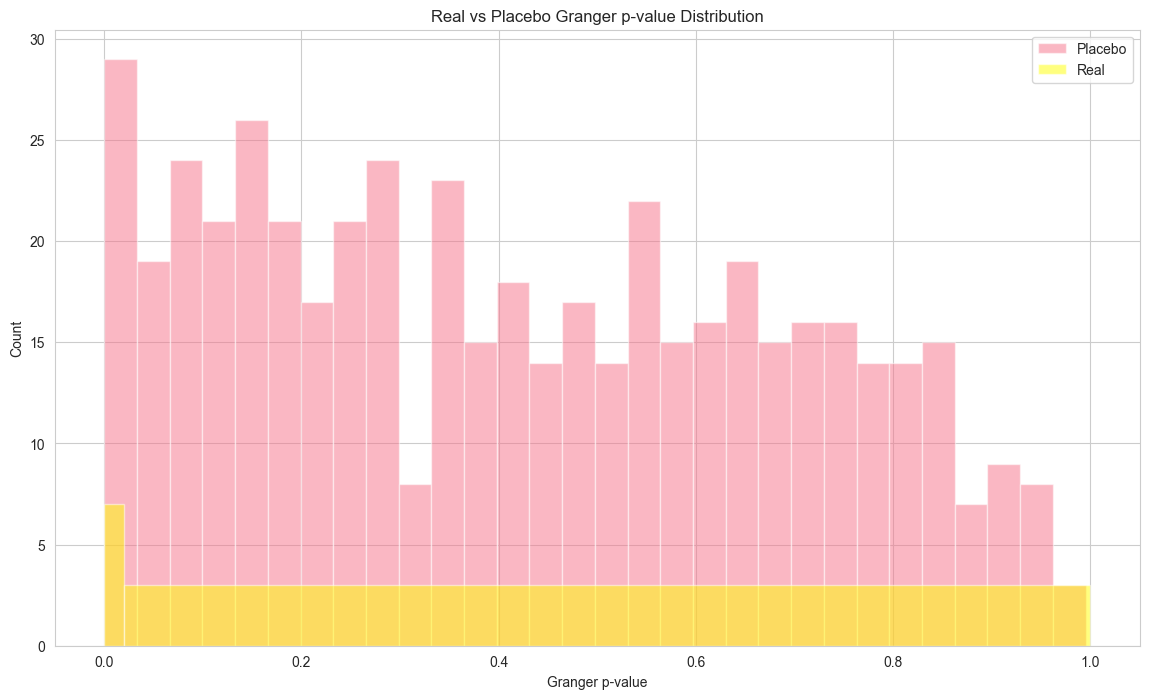

In [73]:
df = pd.read_csv("sectoral_granger_corrected.csv")

# 2. Standardize sector names everywhere
# If your available_groups, prices_clean keys are ['Agricultural', 'Energy', 'Metals', 'Softs', 'Livestock']:
sector_name_map = {
    "Agriculture": "Agricultural", # this is the common mismatch
    "Metals": "Metals",
    "Energy": "Energy",
    "Softs": "Softs",
    "Livestock": "Livestock"
}

# 3. Build sector_pairs with mapped names
sector_pairs = [(sector_name_map.get(f, f), sector_name_map.get(t, t)) for f, t in zip(df.loc[df['fdr_significant'], 'from'], df.loc[df['fdr_significant'], 'to'])]
print("Sector pairs for placebo tests:", sector_pairs)

# 4. Build sector-level seasonal_dict
# This aggregates commodity seasonal signals per sector. Make sure available_groups and prices_clean are defined.
# If STL seasonal components are precomputed, replace sector_series assignment below with mean of seasonal components
seasonal_dict = {}
for sector, comm_list in available_groups.items():
    # Aggregate signal for sector: (here simple mean of prices, adapt as needed)
    sector_series = prices_clean[comm_list].mean(axis=1)
    seasonal_dict[sector] = sector_series

print("Seasonal dict keys:", list(seasonal_dict.keys()))

# 5. Placebo Granger function (same as yours)
def shuffle_series(s):
    return s.sample(frac=1, replace=False).reset_index(drop=True)

def placebo_granger(seasonal_dict, sector_pair, maxlag=2, reps=50):
    s1, s2 = seasonal_dict[sector_pair[0]], seasonal_dict[sector_pair[1]]
    placebo_pvals = []
    for _ in range(reps):
        s1_shuf = shuffle_series(s1)
        s2_shuf = shuffle_series(s2)
        df_null = pd.DataFrame({sector_pair[0]: s1_shuf, sector_pair[1]: s2_shuf}).dropna()
        try:
            gc_results = grangercausalitytests(df_null[[sector_pair[1], sector_pair[0]]], maxlag=maxlag, verbose=False)
            min_p = min(gc_results[lag][0]['ssr_ftest'][1] for lag in range(1, maxlag+1))
            placebo_pvals.append(min_p)
        except:
            continue
    return placebo_pvals

# 6. Run placebo tests for each sector pair
null_results = {}
for pair in sector_pairs:
    if pair[0] in seasonal_dict and pair[1] in seasonal_dict:
        null_results[pair] = placebo_granger(seasonal_dict, pair)
    else:
        print(f"Skipping pair {pair} due to missing seasonal data")

# 7. Visualize histogram of real vs placebo p-values
real_pvals = [
    df.loc[(df['from']==f.replace("Agricultural", "Agriculture")) & (df['to']==t.replace("Agricultural", "Agriculture")), 'min_pval'].values[0]
    for (f, t) in sector_pairs
    if f in seasonal_dict and t in seasonal_dict
]
placebo_pvals_all = [p for plist in null_results.values() for p in plist]

plt.hist(placebo_pvals_all, bins=30, alpha=0.5, label='Placebo')
plt.hist(real_pvals, bins=[0, 0.02, 1], alpha=0.5, color='yellow', label='Real') # Two bins: <0.02, >=0.02
plt.legend()
plt.xlabel('Granger p-value')
plt.ylabel('Count')
plt.title('Real vs Placebo Granger p-value Distribution')
plt.show()

In [74]:
print(real_pvals)

[np.float64(6.556906811830476e-06), np.float64(0.0004026093640661), np.float64(0.0004932073252213), np.float64(0.00055897424228), np.float64(0.0006632493530084), np.float64(0.0116766418227539), np.float64(0.0169276887041654), np.float64(0.0218335702145825), np.float64(0.0231655407177301), np.float64(0.024006917089024)]


In [ ]:
from statsmodels.stats.multitest import multipletests

# Apply FDR correction if not done yet
bonferroni_res = multipletests(df['min_pval'], method='bonferroni', alpha=0.05)
df['bonf_significant'] = bonferroni_res[0]

# Filter for significant sectoral links
df_sig = df[df['bonf_significant']]

# Calculate outgoing and incoming counts per sector
out_degree = df_sig['from'].value_counts().rename('out_degree')
in_degree = df_sig['to'].value_counts().rename('in_degree')

sector_summary = pd.concat([out_degree, in_degree], axis=1).fillna(0).astype(int)

print("=== Sector-wise Incoming and Outgoing Link Counts ===")
print(sector_summary)

sector_summary['net_outflow'] = sector_summary['out_degree'] - sector_summary['in_degree']
print("\n=== Net Outflow (Positive means net 'sender') ===")
print(sector_summary['net_outflow'].sort_values(ascending=False))

print("\n=== Top 10 Significant Sectoral Spillover Links by min_pval ===")
print(df_sig[['from', 'to', 'min_pval']].sort_values('min_pval').head(10))

# Optionally save for reporting
sector_summary.to_csv('outputs/sectoral_link_summary.csv')
df_sig[['from', 'to', 'min_pval']].sort_values('min_pval').to_csv('outputs/sectoral_top_links.csv', index=False)


=== Sector-wise Incoming and Outgoing Link Counts ===
             out_degree  in_degree
Energy                2          1
Livestock             2          2
Agriculture           1          0
Metals                0          1
Softs                 0          1

=== Net Outflow (Positive means net 'sender') ===
Energy         1
Agriculture    1
Livestock      0
Metals        -1
Softs         -1
Name: net_outflow, dtype: int64

=== Top 10 Significant Sectoral Spillover Links by min_pval ===
          from         to  min_pval
0       Energy     Metals  0.000007
1    Livestock     Energy  0.000403
2       Energy  Livestock  0.000493
3    Livestock      Softs  0.000559
4  Agriculture  Livestock  0.000663



Network visualization saved as 'seasonal_spillover_network.png'.


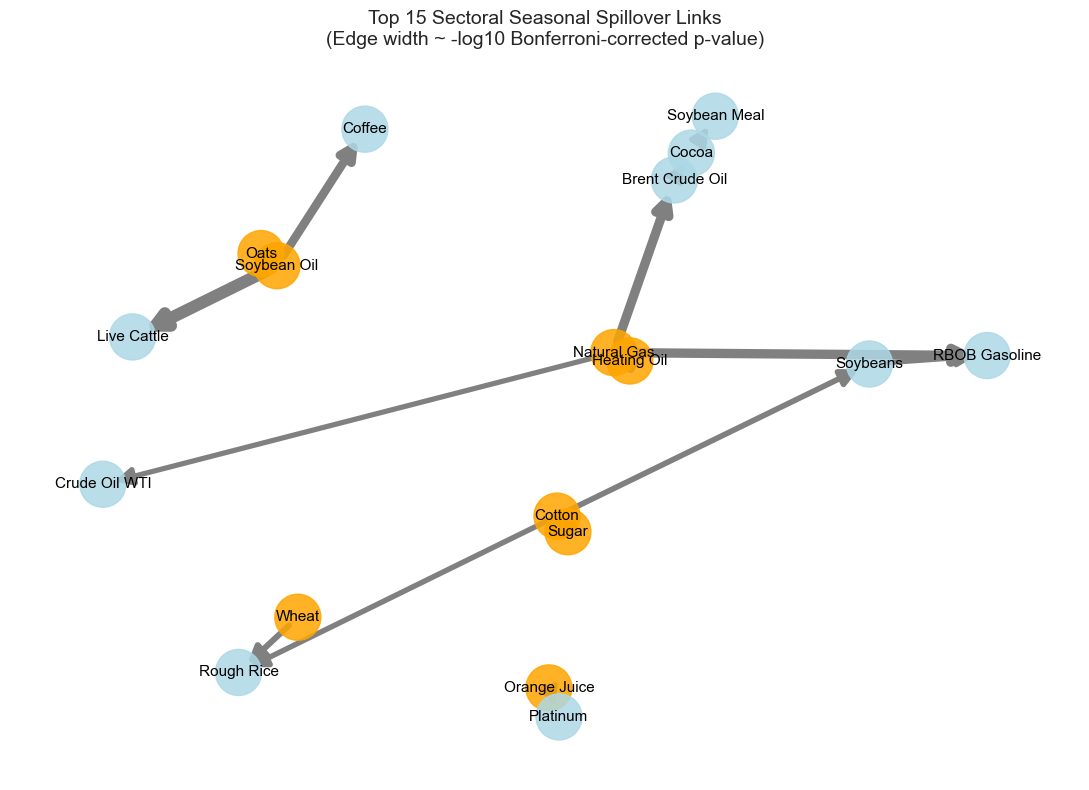

In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests 
import os

# --- Preparation ---
try:
    df = pd.read_csv('outputs/significant_pairwise_seasonal_granger.csv')
except FileNotFoundError:
    print("ERROR: 'significant_pairwise_seasonal_granger.csv' not found. Please run the VAR/Granger Causality pairing code first to generate this file.")
    # You would need to re-run the pairing script here

# --- Multiple Testing Correction (Bonferroni) ---
# FIX: Correctly unpack all 4 return values from multipletests
rejected, pvals_corrected, _, _ = multipletests(df['min_pval'], method='bonferroni', alpha=0.05)
df['bonf_significant'] = rejected
df['pval_corrected'] = pvals_corrected

df.to_csv('outputs/pairwise_seasonal_granger_bonferroni_corrected.csv', index=False)

# --- Compute Edge Strength ---
# Strength is -log10(p-value). Use a minimal value for p=0 to avoid infinite strength.
min_log_val = 1e-300 
df['edge_strength'] = -np.log10(np.where(df['pval_corrected'] == 0.0, min_log_val, df['pval_corrected']))

# --- Filter Edges ---
N = 15
# Filter using the calculated 'bonf_significant' column
top_edges = df[df['bonf_significant']].sort_values('edge_strength', ascending=False).head(N)

if top_edges.empty:
    print(f"No significant seasonal links found after Bonferroni correction (N={N}). The network will be empty.")
else:
    # --- Build Graph ---
    G = nx.DiGraph()
    for _, row in top_edges.iterrows():
        G.add_edge(row['from'], row['to'], weight=row['edge_strength'])

    # --- Node Coloring by Net Flow (Spiller vs. Receiver) ---
    out_degrees = dict(G.out_degree())
    in_degrees = dict(G.in_degree())
    net_outflow = {node: out_degrees.get(node,0) - in_degrees.get(node,0) for node in G.nodes()}
    # Orange nodes are net-spillers (outflow > inflow). Lightblue nodes are net-receivers (inflow > outflow).
    node_colors = [ 'orange' if net_outflow[n]>0 else 'lightblue' for n in G.nodes()]

    plt.figure(figsize=(11, 8))
    pos = nx.spring_layout(G, seed=123, k=0.9 / np.sqrt(len(G.nodes()))) 
    
    nx.draw_networkx_nodes(G, pos, node_size=1100, node_color=node_colors, alpha=0.85)
    nx.draw_networkx_labels(G, pos, font_size=11)
    
    edges = G.edges(data=True)
    # Scale edge width by strength
    weights = [max(1, 1*e[2]['weight']) for e in edges] 
    
    nx.draw_networkx_edges(G, pos, edgelist=edges, width=weights, edge_color='gray', arrowsize=25, arrowstyle='-|>')
    
    plt.title(f"Top {len(top_edges)} Sectoral Seasonal Spillover Links\n(Edge width ~ -log10 Bonferroni-corrected p-value)", fontsize=14)
    plt.axis('off')
    plt.tight_layout()
    plt.savefig('outputs/figures/seasonal_spillover_network.png')
    print("\nNetwork visualization saved as 'seasonal_spillover_network.png'.")

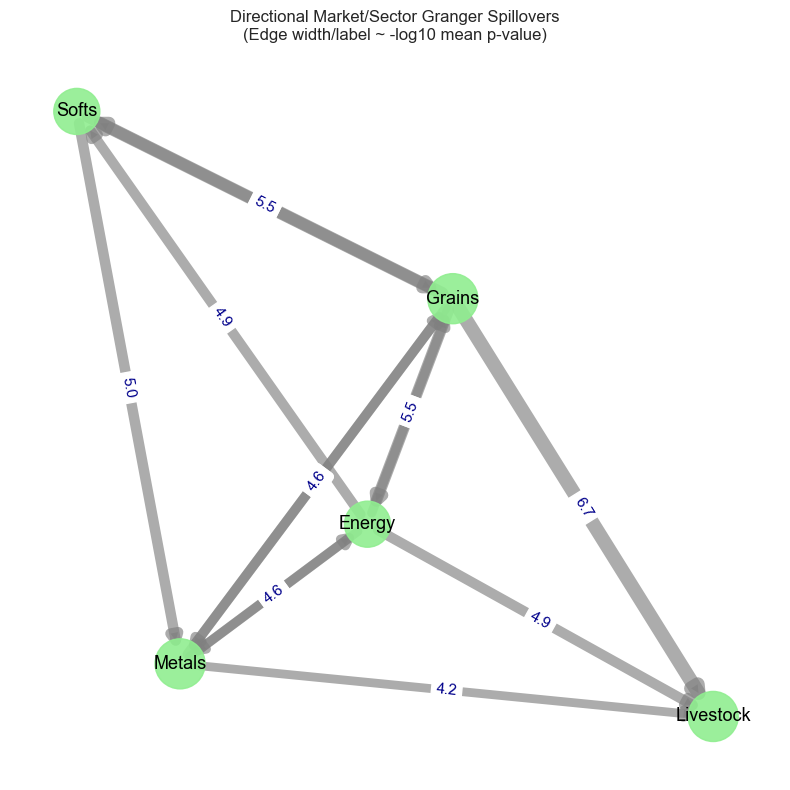

In [78]:
sector_map = {
    # Agricultural Commodities (Grains)
    'Corn': 'Grains',
    'Soybeans': 'Grains',
    'Wheat': 'Grains',
    'Oats': 'Grains',
    'Rough Rice': 'Grains',
    'Soybean Meal': 'Grains',
    'Soybean Oil': 'Grains',

    # Energy
    'Crude Oil WTI': 'Energy',
    'Brent Crude Oil': 'Energy',
    'Heating Oil': 'Energy',
    'RBOB Gasoline': 'Energy',
    'Natural Gas': 'Energy',

    # Metals
    'Gold': 'Metals',
    'Silver': 'Metals',
    'Copper': 'Metals',
    'Platinum': 'Metals',

    # Softs
    'Coffee': 'Softs',
    'Cotton': 'Softs',
    'Sugar': 'Softs',
    'Cocoa': 'Softs',
    'Orange Juice': 'Softs',

    # Livestock
    'Live Cattle': 'Livestock',
    'Feeder Cattle': 'Livestock',
    'Lean Hogs': 'Livestock'
}

# Load and bonf-correct as before
df = pd.read_csv('outputs/significant_pairwise_seasonal_granger.csv')
rejected, pvals_corrected, _, _ = multipletests(df['min_pval'], method='bonferroni', alpha=0.05)
df['fdr_significant'] = rejected
df_sig = df[df['fdr_significant']].copy()

# Map commodities to market sectors, handling missing mappings
df_sig['from_sector'] = df_sig['from'].map(sector_map)
df_sig['to_sector'] = df_sig['to'].map(sector_map)

# Drop rows where sector mapping failed (e.g. from custom tickers etc)
df_sig = df_sig.dropna(subset=['from_sector','to_sector'])

# Group by sector-pairs: count links and average strength
sector_edges = df_sig.groupby(['from_sector', 'to_sector']).agg(
    n_links = ('min_pval','size'),
    avg_strength = ('min_pval', lambda x: -np.log10(x).mean())
).reset_index()

# Optionally exclude self-links:
sector_edges = sector_edges[sector_edges['from_sector'] != sector_edges['to_sector']]

# Build network graph
G = nx.DiGraph()
for _, row in sector_edges.iterrows():
    G.add_edge(row['from_sector'], row['to_sector'], weight=row['avg_strength'], count=row['n_links'])

import matplotlib.pyplot as plt
import networkx as nx

plt.figure(figsize=(8, 8))

pos = nx.spring_layout(G, seed=11, k=2)

node_sizes = [700 + 200*G.in_degree(n) for n in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color='lightgreen', alpha=0.9)
nx.draw_networkx_labels(G, pos, font_size=13)

edges = G.edges(data=True)
widths = [max(1, 1.5*e[2]['weight']) for e in edges]  # reduced scale!
nx.draw_networkx_edges(
    G, pos, edgelist=edges,
    width=widths, edge_color='gray',
    arrows=True, arrowstyle='-|>',
    arrowsize=14, alpha=0.65  # smaller arrows, more transparent
)

edge_labels = { (e[0], e[1]): f"{e[2]['weight']:.1f}" for e in edges }
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='darkblue', font_size=11)

plt.title("Directional Market/Sector Granger Spillovers\n(Edge width/label ~ -log10 mean p-value)")
plt.axis('off')
plt.tight_layout()
plt.show()

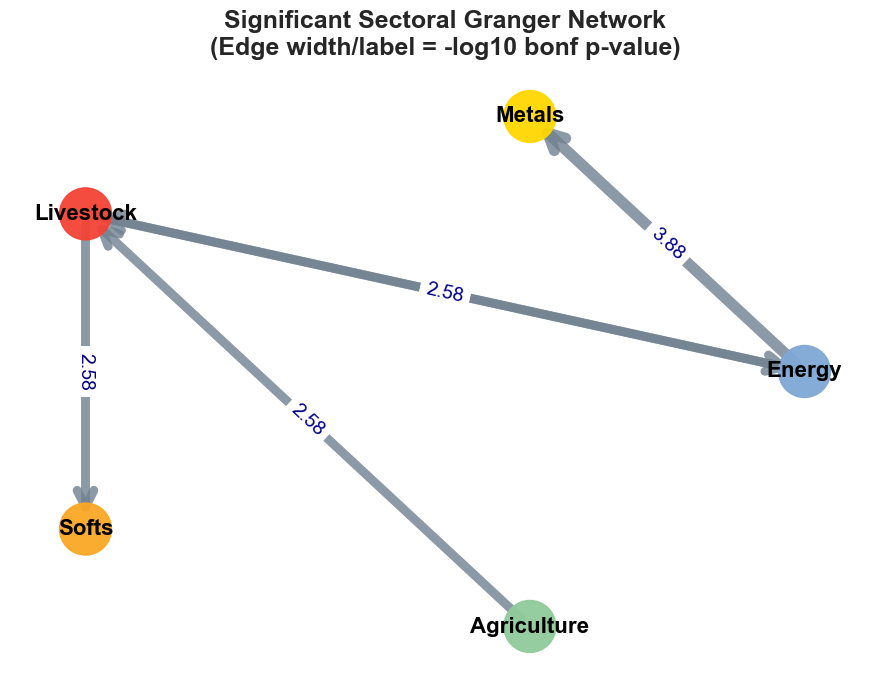

In [80]:
# Use distinct colors if desired
sector_colors = {
    'Agriculture': '#8FCB9B',
    'Energy': '#7FA8D4',
    'Metals': '#FFD700',
    'Softs': '#F9A825',
    'Livestock': '#F44336'
}
node_colors = [sector_colors.get(n, '#AAAAAA') for n in G.nodes()]

plt.figure(figsize=(9, 7))
pos = nx.circular_layout(G)  # For clarity with few nodes

# Node styling
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=1400, alpha=0.95)
nx.draw_networkx_labels(G, pos, font_size=16, font_weight='bold')

# Edge widths
edges = G.edges(data=True)
widths = [max(2, min(8, e[2]['weight'] * 2.5)) for e in edges]  # Scaled for visibility

# Edge drawing with gradient color (optional)
nx.draw_networkx_edges(
    G, pos, edgelist=edges, width=widths, edge_color='slategray',
    arrowsize=30, arrowstyle='->', alpha=0.8
)

# Edge label formatting
edge_labels = { (e[0], e[1]): f"{e[2]['weight']:.2f}" for e in edges }
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='darkblue', font_size=14)

plt.title('Significant Sectoral Granger Network\n(Edge width/label = -log10 bonf p-value)', fontsize=18, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()
